# ASGN2703 – Anomaly Detection in Industrial Equipment Sensor Data (Isolation Forest)
**Objective:** detect anomalies in industrial sensor readings with **Isolation Forest**, evaluate the model, visualise normal vs. anomalous readings and recommend maintenance actions.

All reusable logic (preprocessing, model, metrics, plots) lives in `anomaly_utils.py`; this notebook runs the workflow and explains each step.

**Outline:** 1 Load · 2 Preprocess · 3 Explore · 4 Model · 5 Evaluate · 6 Visualise · 7 Discuss

## 1. Setup and data loading

In [1]:
import json, os, warnings
import pandas as pd, seaborn as sns
import anomaly_utils as au

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
results = {}                      # metrics collected here, saved to results.json for the PDF report

raw = pd.read_csv("industrial_sensor_data.csv")
print("Shape:", raw.shape)
raw.describe().T.round(2)

Shape: (3000, 10)


,count,mean,std,min,25%,50%,75%,max
SensorID,2961.0,1501.46,866.23,1.00,750.00,1505.00,2252.00,3000.00
Temperature,2956.0,57.52,24.80,15.00,35.93,58.00,79.23,99.98
Pressure,2957.0,27.26,12.91,5.00,16.11,26.98,38.21,49.98
Vibration,2963.0,4.87,2.86,0.00,2.41,4.82,7.29,9.99
Humidity,2940.0,55.23,20.19,20.00,37.79,55.09,72.95,89.98
FlowRate,2950.0,50.35,28.68,1.12,25.21,49.59,75.98,99.98
PowerConsumption,2951.0,251.60,143.46,0.13,128.84,255.76,373.17,499.96
RuntimeHours,2950.0,1026.23,577.57,1.22,541.60,1020.80,1521.78,1999.74
FaultFlag,2961.0,0.48,0.50,0.00,0.00,0.00,1.00,1.00


## 2. Preprocessing
**2a. Missing values.** Every column has ~1–2 % missing values. Strategy: rebuild `SensorID` from the sequential row order (verified), fill `LastServiceDate` from neighbouring rows (the data is date-ordered), median-impute sensor columns (robust to the outliers we want to find). The `FaultFlag` label is **never imputed**; unlabelled rows are used for training but excluded from the metrics.

,Humidity,FlowRate,RuntimeHours,PowerConsumption,Temperature,Pressure,SensorID,FaultFlag,Vibration,LastServiceDate
% missing,2.0,1.67,1.67,1.63,1.47,1.43,1.3,1.3,1.23,1.23


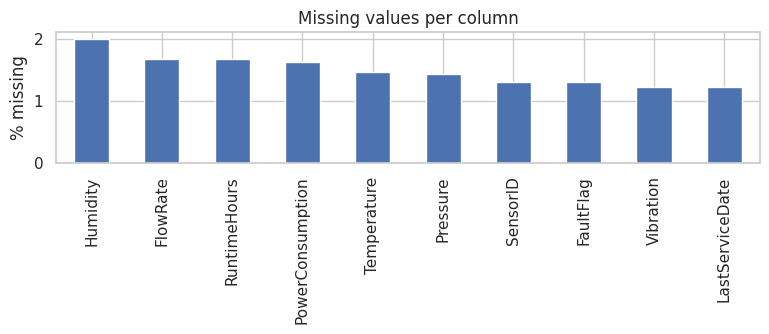

Rows without a label (excluded from metrics only): 39


In [2]:
missing_pct = (raw.isna().mean() * 100).round(2).sort_values(ascending=False)
display(missing_pct.to_frame("% missing").T)
results.update(rows_total=len(raw), missing_total_cells=int(raw.isna().sum().sum()),
               rows_with_any_missing=int(raw.isna().any(axis=1).sum()))
au.plot_missing(missing_pct, "figures/01_missing_values.png")

df = au.add_service_age(au.impute_missing(raw))        # 2a imputation + 2b service-age feature
print("Rows without a label (excluded from metrics only):", (~df["has_label"]).sum())

**2b. Feature engineering.** `LastServiceDate` becomes `DaysSinceService` (days before the latest date in the data).

**2c. Noise and extreme values.** Check the IQR rule, then winsorise at the 0.5 / 99.5 percentiles to limit spikes without deleting rows (Isolation Forest is already outlier-robust, so clipping is kept mild). A rolling median is used for plotting only.

In [3]:
results["iqr_outliers"] = {c: au.count_iqr_outliers(df[c]) for c in au.FEATURES}
print("IQR outliers per feature:", results["iqr_outliers"])
df, results["values_winsorised"] = au.winsorise(df, au.FEATURES)
print("Values winsorised:", results["values_winsorised"])

IQR outliers per feature: {'Temperature': 0, 'Pressure': 0, 'Vibration': 0, 'Humidity': 0, 'FlowRate': 0, 'PowerConsumption': 0, 'RuntimeHours': 0, 'DaysSinceService': 0}
Values winsorised: 210


**2d. Normalisation.** Z-score standardisation, so PCA and the feature-profile analysis treat all features equally.

In [4]:
X, X_df = au.standardise(df, au.FEATURES)
X_df.describe().loc[["mean", "std"]].round(3)

,Temperature,Pressure,Vibration,Humidity,FlowRate,PowerConsumption,RuntimeHours,DaysSinceService
mean,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 3. Exploratory analysis

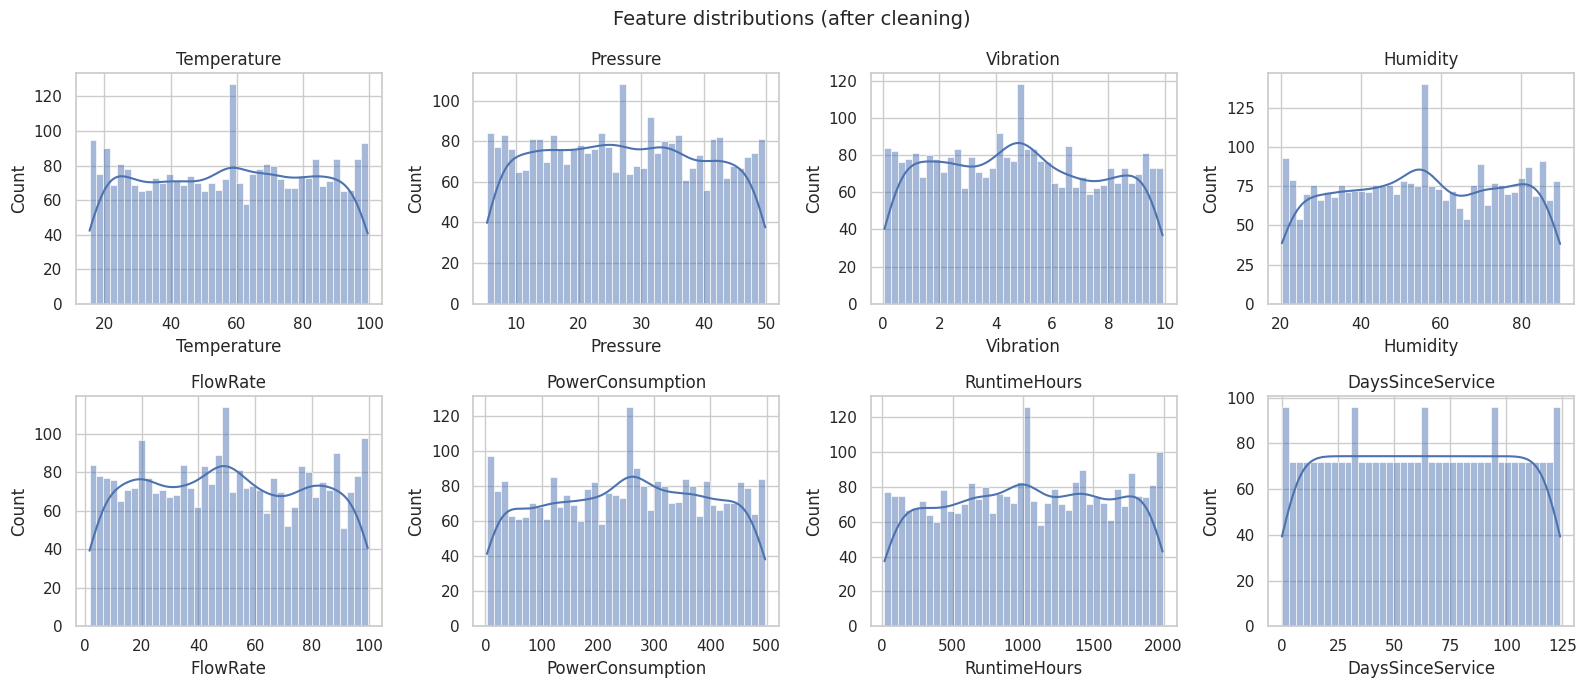

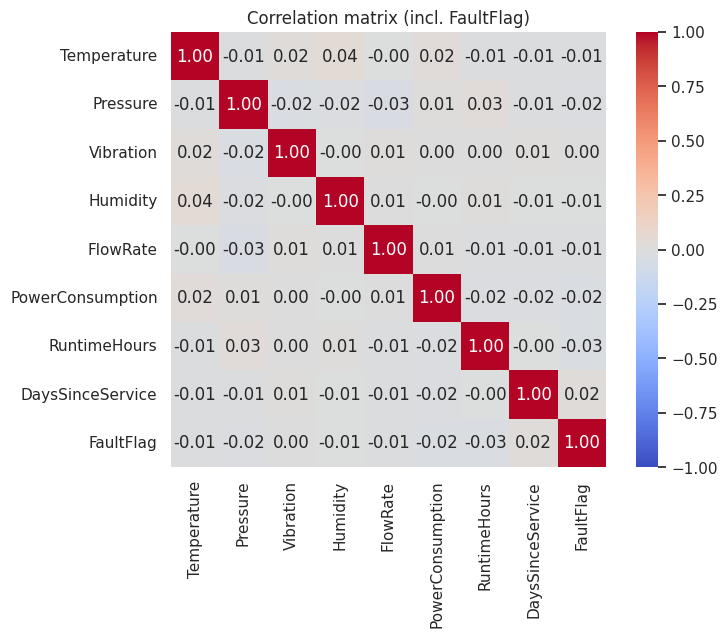

Fault rate: 47.6% | max |corr| of any feature with FaultFlag: 0.025


In [5]:
au.plot_distributions(df, "figures/02_distributions.png")
corr = df[au.FEATURES + ["FaultFlag"]].corr()
au.plot_correlation(corr, "figures/03_correlation.png")
results["max_abs_corr_with_fault"] = float(corr["FaultFlag"].drop("FaultFlag").abs().max())
results["fault_rate"] = float(df["FaultFlag"].mean())
print(f"Fault rate: {results['fault_rate']:.1%} | max |corr| of any feature with FaultFlag: {results['max_abs_corr_with_fault']:.3f}")

**Observations.** Features are broadly uniform and mutually uncorrelated, and **no sensor is linearly related to `FaultFlag`**. About 48 % of units are flagged faulty, far above the 1–5 % anomaly rate Isolation Forest is designed for. This shapes how the results should be read.

## 4. Isolation Forest model
Anomalies are "few and different", so random splits isolate them in fewer steps (shorter path → higher anomaly score). Settings: 300 trees, `max_samples="auto"`, **`contamination=0.05`** (conventional anomaly rate, as the true rate is unknown); a sensitivity sweep follows in Section 5.

In [6]:
model = au.fit_isolation_forest(X, contamination=0.05)
df["iso_pred"], df["iso_score"] = au.predict_anomalies(model, X)       # 1 = anomaly
print(f"Anomalies flagged: {df['iso_pred'].sum()} ({df['iso_pred'].mean():.1%})")
df.sort_values("iso_score", ascending=False)[["SensorID", "iso_score", "iso_pred", "FaultFlag"]].head(10)

Anomalies flagged: 150 (5.0%)


,SensorID,iso_score,iso_pred,FaultFlag
117,118,0.603732,1,0.0
2774,2775,0.595311,1,0.0
2970,2971,0.594049,1,0.0
2844,2845,0.590406,1,0.0
2427,2428,0.589647,1,0.0
2909,2910,0.589558,1,0.0
1016,1017,0.587962,1,0.0
12,13,0.585611,1,0.0
2743,2744,0.585477,1,0.0
2803,2804,0.583368,1,0.0


## 5. Evaluation
`FaultFlag = 1` is the ground truth for "anomalous". Precision, recall and F1 depend on the threshold; ROC-AUC uses the continuous score (random = 0.5).

{'precision': 0.415, 'recall': 0.043, 'f1': 0.078, 'roc_auc': 0.478}


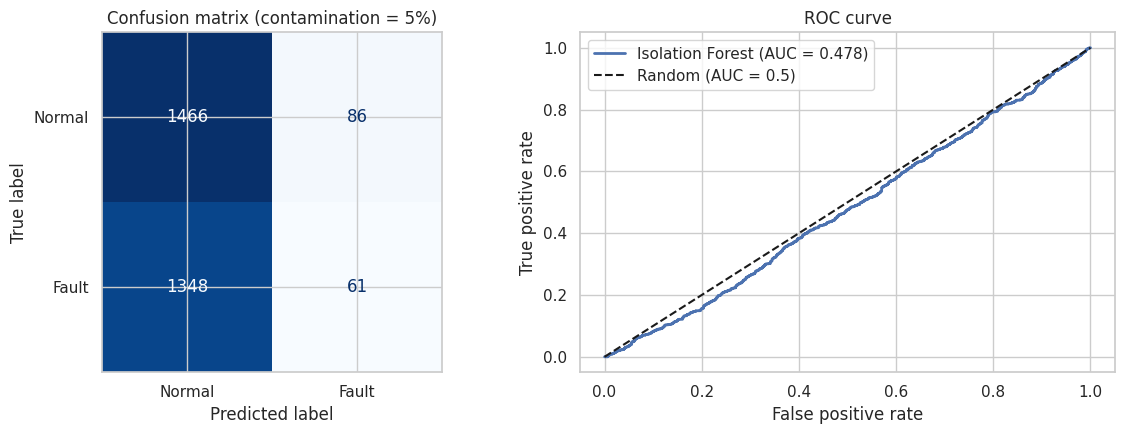

In [7]:
labelled = df[df["has_label"]]
y_true, y_pred, y_score = labelled["FaultFlag"].astype(int), labelled["iso_pred"], labelled["iso_score"]

metrics = au.evaluate(y_true, y_pred, y_score)
results["main"] = dict(contamination=0.05, n_eval=len(labelled), n_flagged=int(y_pred.sum()), **metrics)
print({k: round(v, 3) for k, v in metrics.items()})
au.plot_evaluation(y_true, y_pred, y_score, metrics["roc_auc"], "figures/04_evaluation.png")
from sklearn.metrics import confusion_matrix
results["confusion_matrix"] = confusion_matrix(y_true, y_pred).tolist()

In [8]:
# Sensitivity to the contamination parameter (last level = observed fault rate)
levels = [0.01, 0.05, 0.10, 0.20, 0.30, results["fault_rate"]]
sweep = au.contamination_sweep(X, df["has_label"].values, y_true, levels)
results["sweep"] = sweep.to_dict("records")
sweep

,contamination,precision,recall,f1,flagged
0,0.010,0.379,0.008,0.015,29
1,0.050,0.415,0.043,0.078,147
2,0.100,0.424,0.089,0.148,297
3,0.200,0.425,0.178,0.251,590
4,0.300,0.446,0.279,0.343,882
5,0.476,0.463,0.462,0.462,1407


In [9]:
# Sanity check: can ANY model predict FaultFlag from these features? (supervised upper-bound view)
results["rf_cv_auc_mean"], results["rf_cv_auc_std"] = au.supervised_baseline_auc(X[df["has_label"].values], y_true)
print(f"Supervised Random Forest 5-fold ROC-AUC: {results['rf_cv_auc_mean']:.3f} ± {results['rf_cv_auc_std']:.3f}")

Supervised Random Forest 5-fold ROC-AUC: 0.497 ± 0.011


**Reading the results.** If even a supervised model cannot beat ROC-AUC ≈ 0.5, `FaultFlag` carries **no recoverable signal** in these features, so no unsupervised detector can match it; the weak scores reflect the data, not a defect in the model. Isolation Forest can still do its real job, ranking readings by how unusual they are, which is visualised next.

## 6. Visualisation
### 6a. Time-series (record order as a time proxy; red = anomaly)

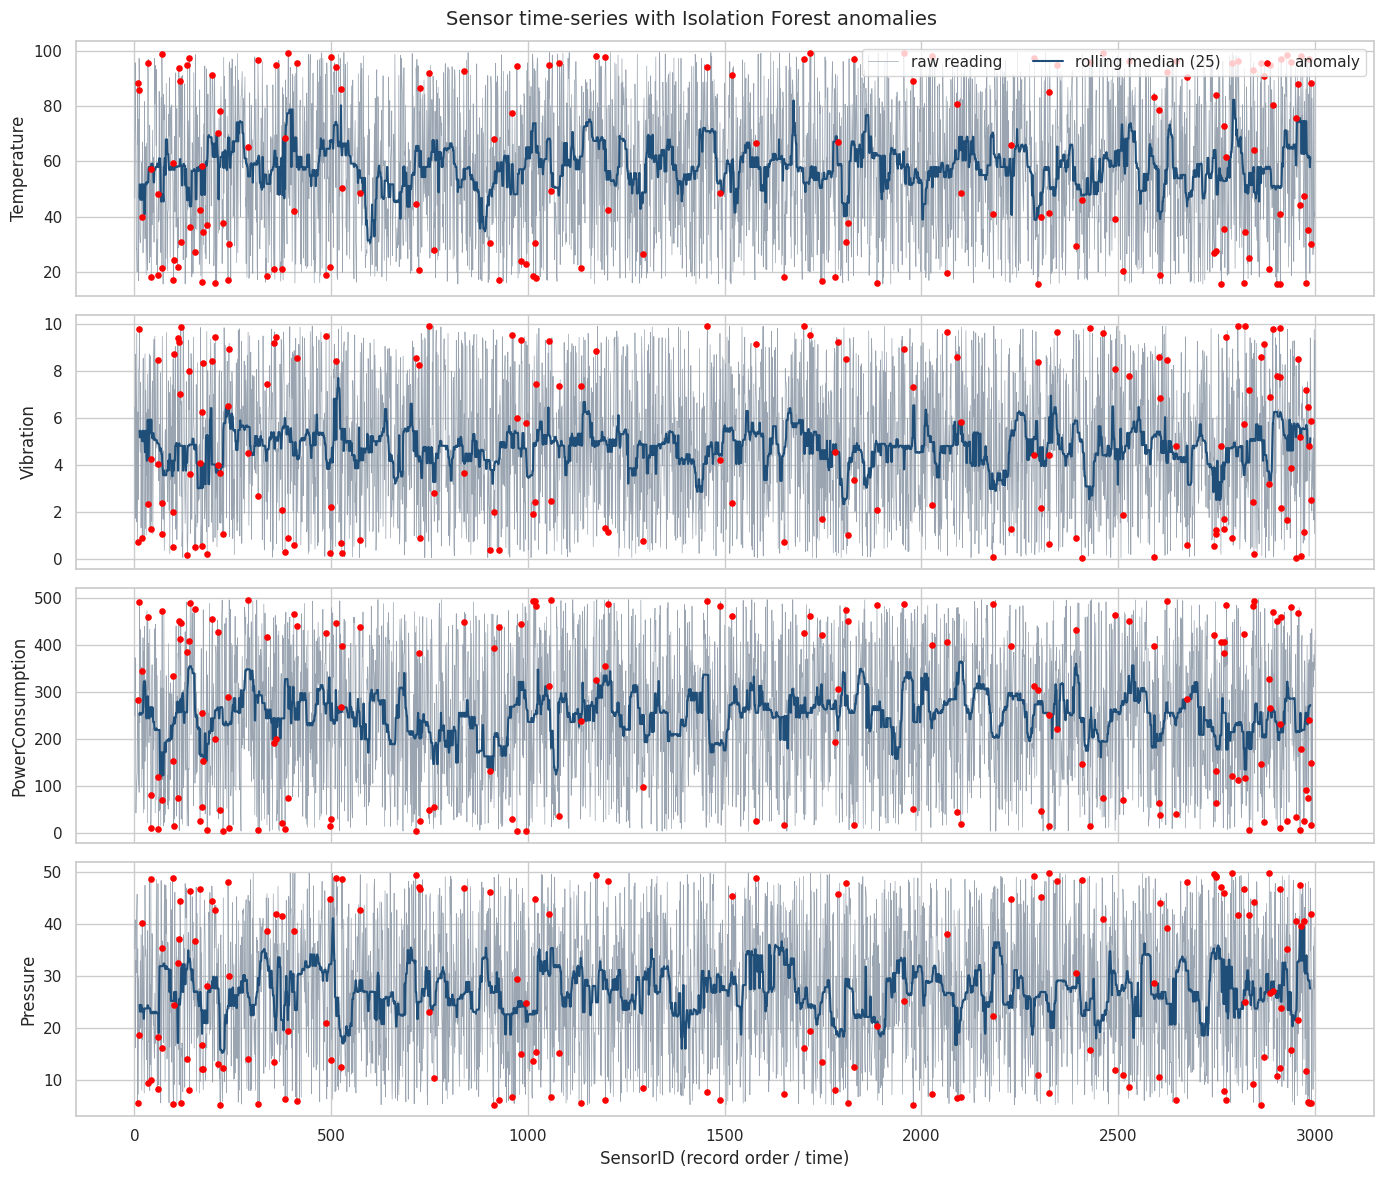

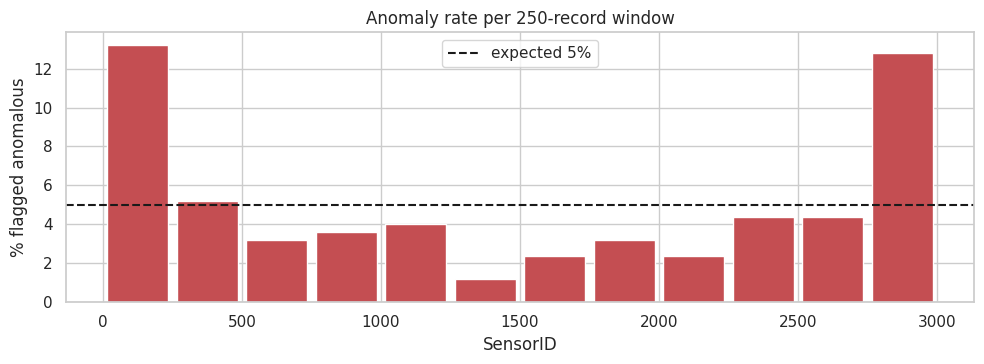

In [10]:
au.plot_timeseries(df, "figures/05_timeseries.png")
au.plot_anomaly_rate(df, "figures/06_anomaly_rate.png");

### 6b. Scatter plots – normal vs anomalous

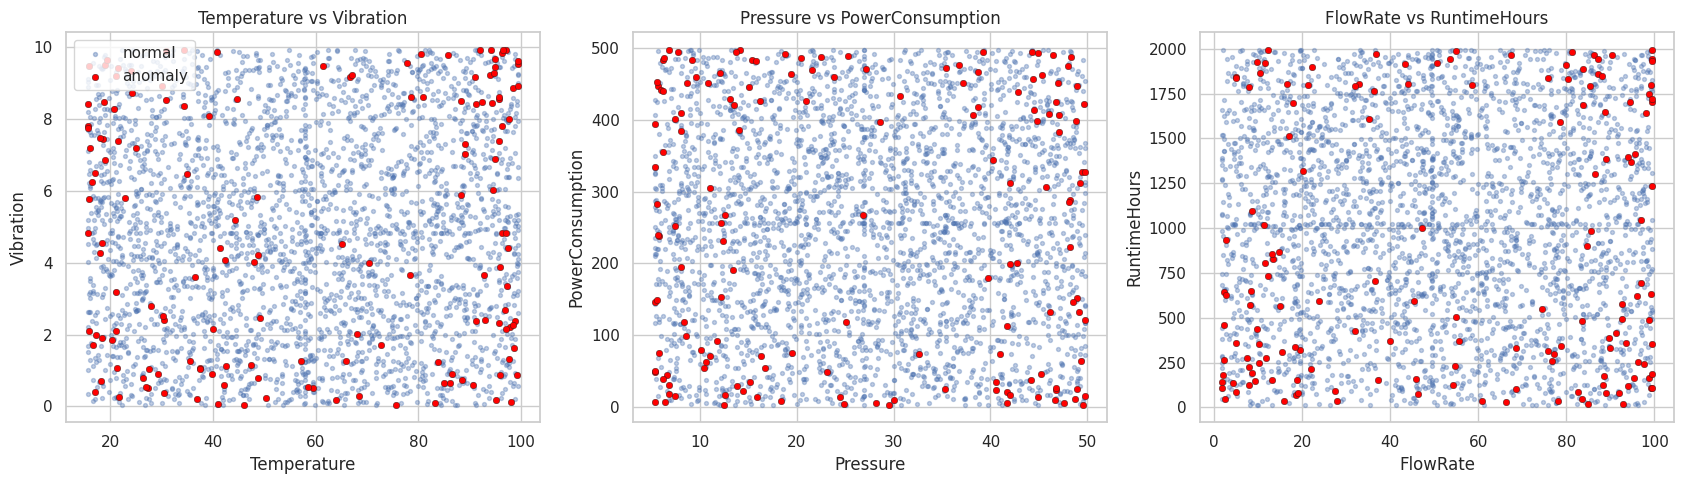

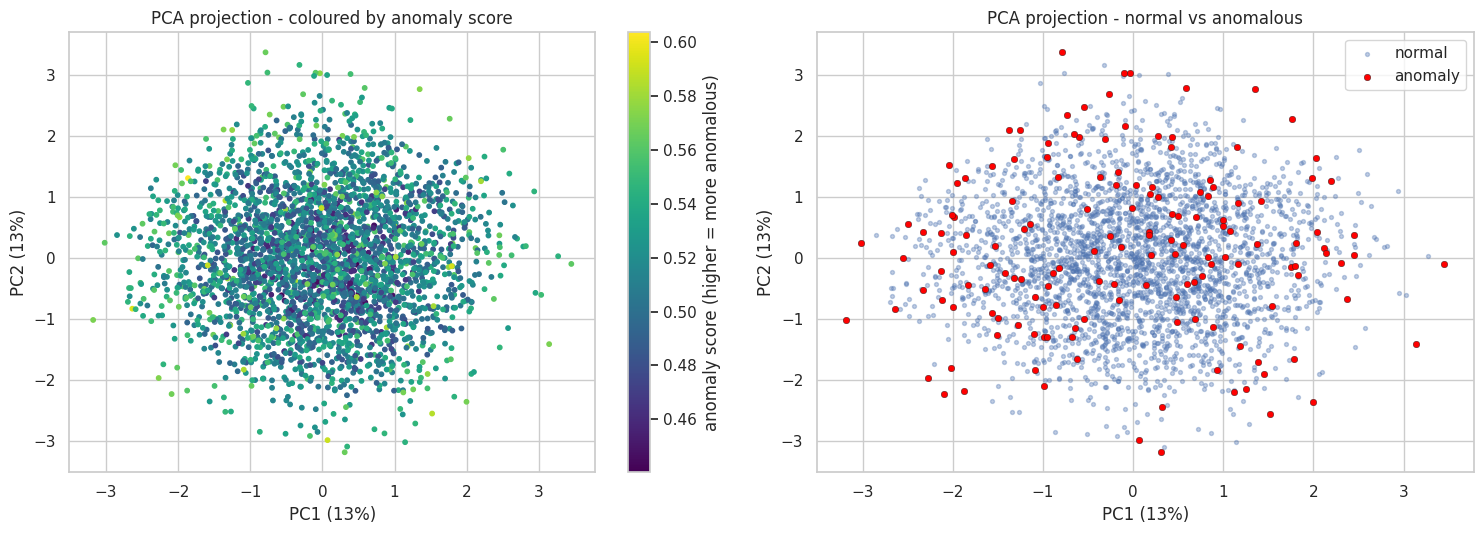

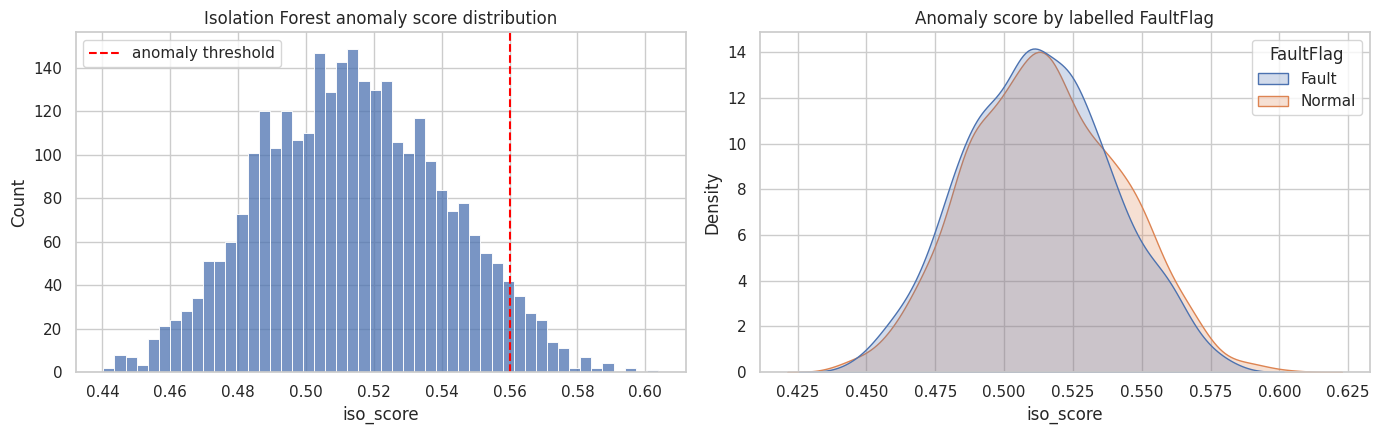

In [11]:
au.plot_scatter_pairs(df, "figures/07_scatter_pairs.png")
au.plot_pca(X, df, "figures/08_pca.png")
au.plot_scores(df, df[df["has_label"]], "figures/09_scores.png")

### 6c. What makes flagged readings unusual?

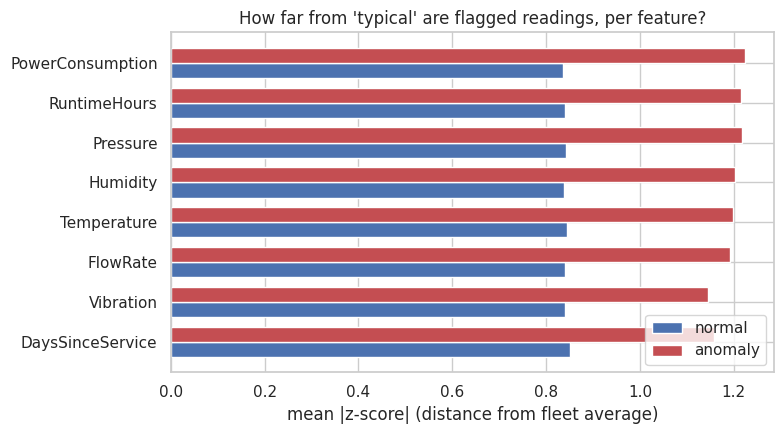

,anomalies,normal,ratio
DaysSinceService,1.158,0.851,1.361
Vibration,1.144,0.839,1.363
FlowRate,1.192,0.841,1.417
Temperature,1.198,0.844,1.420
Humidity,1.202,0.838,1.435
Pressure,1.217,0.843,1.444
RuntimeHours,1.216,0.839,1.448
PowerConsumption,1.225,0.836,1.465


In [12]:
profile = au.feature_profile(X_df, df["iso_pred"])
au.plot_feature_profile(profile, "figures/10_feature_profile.png")

extreme = (X_df.abs() > 1.5).sum(axis=1)                # features far from typical, per reading
results["mean_extreme_features_anom"] = float(extreme[df.iso_pred == 1].mean())
results["mean_extreme_features_normal"] = float(extreme[df.iso_pred == 0].mean())
results["feature_profile"] = profile.round(3).to_dict("index")
profile.round(3)

## 7. Discussion: causes of anomalies and recommendations

### 7a. What the results say
* **Model vs. `FaultFlag`.** At 5 % contamination Isolation Forest flags ~147 readings with precision ≈ 0.41, recall ≈ 0.04, F1 ≈ 0.08 and ROC-AUC ≈ 0.48. Raising contamination to the fault rate (47.6 %) only lifts precision/recall/F1 to ≈ 0.46, which is what random guessing achieves at a ~48 % base rate.
* **This is a data property, not a model failure.** A supervised Random Forest (5-fold CV) also scores ROC-AUC ≈ 0.50, and no sensor correlates with `FaultFlag` (max |r| ≈ 0.03). The sensors contain no recoverable information about the fault label.
* **What the model did find.** The features are close to uniformly distributed and independent, with no IQR outliers. Isolation Forest therefore flags readings in the *corners* of the operating envelope: unusual combinations of several readings at once, rather than single extreme values. The feature profile shows these points are further from the fleet average on every dimension, not on one specific sensor.
* **Service age drives the only temporal pattern.** The anomaly rate is about 13 % in the first and last 250 records but only 1–5 % in between (Section 6a). `DaysSinceService` falls steadily from 124 to 0 days across the record order, so the oldest-serviced and most recently serviced units sit at the extremes of that feature and are isolated more easily. 25 % of flagged units have service age in the extreme ranges (≤ 5 or ≥ 120 days) versus 8 % of normal units.

### 7b. Potential causes of anomalies (hypotheses to verify – the data alone cannot prove causation)
| Signal pattern | Plausible physical cause |
|---|---|
| High Vibration + high Temperature | Bearing wear, misalignment, imbalance, lubrication failure |
| High Pressure with low FlowRate | Blockage, fouled filter, partly closed valve |
| Low Pressure with high FlowRate | Leak, pipe/seal failure, pump cavitation |
| High PowerConsumption with normal output | Motor inefficiency, friction, electrical fault |
| High Temperature + high Humidity | Cooling or ventilation failure, condensation risk |
| Large DaysSinceService with abnormal readings | Overdue maintenance / wear accumulation |
| Isolated single-sensor spikes | Sensor drift, calibration error, loose wiring (measurement, not equipment, fault) |

### 7c. Recommendations
1. **Fix the labelling before relying on `FaultFlag`.** A ~48 % fault rate that no sensor explains suggests the flag is defined differently from what the sensors measure (e.g. a work-order or inspection flag), or is mis-recorded. Confirm its definition with the maintenance team.
2. **Use the anomaly score as a triage list, not a verdict.** Inspect the top-scoring units (exported to `anomaly_results.csv`) and record the outcome. Those confirmed findings become real labels for supervised models.
3. **Check instrumentation first.** Cross-check flagged readings against neighbouring sensors and recalibrate those with single-channel spikes, since these are often sensor faults.
4. **Condition-based maintenance.** Set alert thresholds on Vibration, Temperature and PowerConsumption jointly, and prioritise service for units with long time since service that are also flagged.
5. **Improve data quality.** About 1–2 % of values were missing in every column (448 cells, 422 rows); add collection-pipeline monitoring and timestamped readings (a true time index) so temporal trends and drift can be modelled.
6. **Operationalise.** Re-fit monthly, tune `contamination` to the review capacity of the maintenance team (e.g. 2–5 %), and track precision of reviewed alerts over time.

### 7d. Limitations
Contamination is a tuning choice; the record order is only a proxy for time; the dataset appears to carry no real fault structure (uniform, independent features), so conclusions about physical causes are hypotheses rather than findings.

## 8. Save outputs

In [13]:
with open("results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
df.sort_values("iso_score", ascending=False)[["SensorID"] + au.FEATURES + ["FaultFlag", "iso_score", "iso_pred"]] \
  .to_csv("anomaly_results.csv", index=False)
print("Saved results.json and anomaly_results.csv")

Saved results.json and anomaly_results.csv
